# Pair B, Phase II (AI-aided). What did Model B learn?

*AI-aided: scripts and notebook drafted with Claude Code, every number checked against the computed outputs; see `ai-interactions/phase2_ai_log.md`.*

Phase I kept the box closed and found **how** Model B behaves. Phase II opens Bio_ClinicalBERT and explains **why**. Every section starts from a Phase I finding.

Model B: record → text template → Bio_ClinicalBERT (12 layers) → mean of all token vectors (768-D) → 10 nearest other patients (cosine) → majority vote.

| Phase I finding (black box) | Phase II question (inside) | Technique | Section |
|---|---|---|---|
| Neighbours are almost equally far away (median d10 0.0006) | What does the space look like? | Embedding geometry per layer | 2 |
| HbA1c edit replaces 8.2 of 10 neighbours, sex swap 4.1 | Why does one edit move a stay out of its neighbourhood? | Edit shift vs. neighbourhood radius; tokenizer | 3 |
| Neighbours share specialty (+0.69) and payer (+0.66), not the outcome (+0.01) | Which fields shape the space? | Variance share per field; **Shapley values** over fields | 4 |
| — | Which tokens inside the text carry the similarity? | **Integrated Gradients** (saliency) | 5 |
| Rare pathways never predicted, outcome lift +0.01 | Is the outcome encoded at all, and where? | **Concept probes per layer** (network-dissection style); layer projection | 6 |
| One stay's prediction flips after the HbA1c edit | How is one stay classified, step by step? | Explaining by example (walk-through) | 7 |
| Accuracy 63.0 %, below the majority class | Where inside does the classification form? | Classifier per layer; **Grad-CAM** per layer; **ICE / PDP** | 8 |

Heavy computations are in `scripts/01–07` (outputs are cached in `outputs/`, embeddings in `shared/data_cache/`, both gitignored). This notebook only reads them.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import Image, display

OUT, FIG = Path("outputs"), Path("figures")
DATA = Path("../../shared/data")
COL = {"B": "#B33A2E", "B2": "#E07B39", "grey": "#9AA0A6", "dark": "#333333"}
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})
cohort = pd.read_parquet(DATA / "cohort_encounters.parquet")
retrieval = pd.read_parquet(DATA / "retrieval_results.parquet")
flips = pd.read_parquet(DATA / "counterfactual_flips.parquet")
df = cohort.merge(retrieval.drop(columns=["patient_nbr", "true_next_pathway"]), on="encounter_id").merge(
    flips.drop(columns=["patient_nbr"]), on="encounter_id")
print(f"{len(df):,} stays")

30,248 stays


## 1. Reproducing Model B

`scripts/01_embed_layers.py` re-runs Bio_ClinicalBERT on all 30,248 texts and keeps the mean-pooled vector after **every** layer (13 × 768). Before explaining the model we check it is the same model: recomputed neighbours match the Phase I neighbours for **9.97 of 10** on average (97.1% identical sets; the rest are near-ties after storing vectors in float16), median distance to the 10th neighbour 0.00060 vs. 0.00060.

## 2. The space is a narrow cone

How similar are two **random** stays in Model B's space?

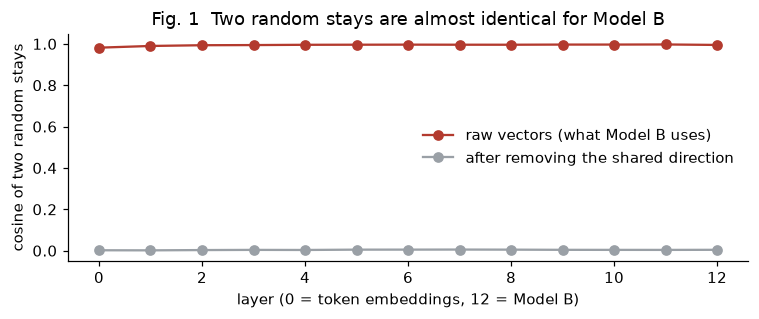

layer,0,1,2,3,4,5,6,7,8,9,10,11,12
random_pair_cosine,0.9817,0.9899,0.9935,0.9943,0.9956,0.9960,0.9964,0.9960,0.9959,0.9966,0.9967,0.9972,0.9949
random_pair_cosine_centered,0.0021,0.0017,0.0030,0.0039,0.0035,0.0051,0.0052,0.0055,0.0051,0.0042,0.0040,0.0038,0.0043
mean_direction_share,0.9815,0.9899,0.9935,0.9942,0.9956,0.9960,0.9964,0.9960,0.9959,0.9966,0.9967,0.9972,0.9949


In [2]:
an = pd.read_csv(OUT / "anisotropy.csv")
fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(an.layer, an.random_pair_cosine, "o-", color=COL["B"], label="raw vectors (what Model B uses)")
ax.plot(an.layer, an.random_pair_cosine_centered, "o-", color=COL["grey"], label="after removing the shared direction")
ax.set_xlabel("layer (0 = token embeddings, 12 = Model B)"); ax.set_ylabel("cosine of two random stays")
ax.set_title("Fig. 1  Two random stays are almost identical for Model B")
ax.legend(frameon=False); plt.tight_layout(); plt.show()
an.round(4).set_index("layer").T

**Fig. 1.** In the layer Model B uses (12), two random stays have a cosine similarity of **0.995**; 99.5% of every vector's length is one direction shared by all stays. After removing that shared direction, random stays are unrelated (0.004). So only about half a percent of the vector carries the patient. This is why Phase I found tiny, crowded neighbourhoods (median distance to the 10th neighbour 0.0006): all stays live in a very narrow cone. Section 5 shows where the shared direction comes from.

## 3. Why one edit replaces the whole neighbourhood (RQ4)

For each edit, `scripts/02_geometry_edits.py` re-encodes the edited text and measures how far the stay moves (cosine distance original → edited) **relative to the distance of its 10th neighbour**. Ratio > 1: the edited stay lands outside its old neighbourhood.

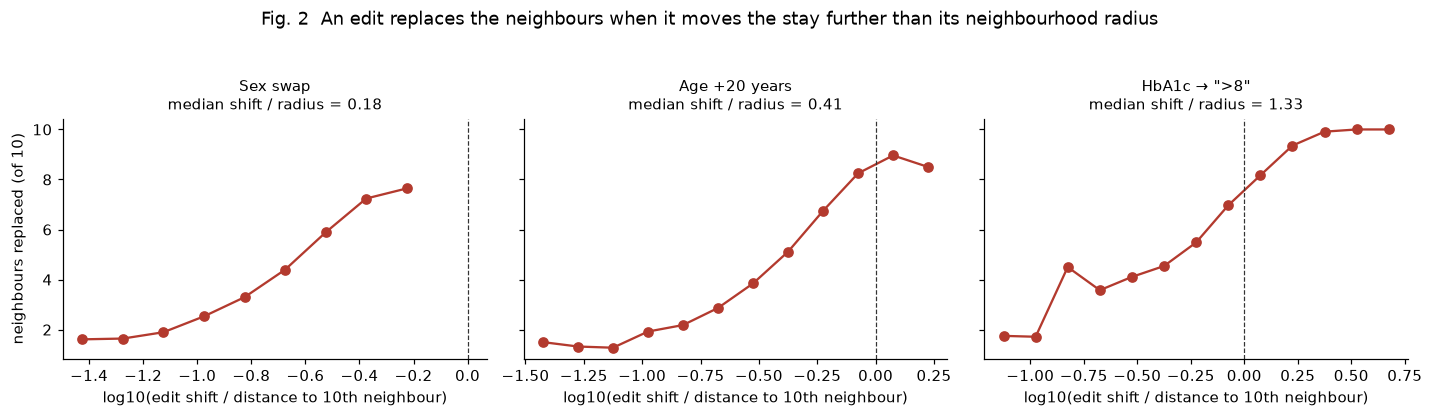

,median shift,median shift / d10,Spearman with flips,mean flips (Phase I)
Sex swap,0.00011,0.18477,0.72784,4.14999
Age +20 years,0.00026,0.40693,0.72983,5.11165
"HbA1c → "">8""",0.00075,1.33482,0.65658,8.21615


In [3]:
es = pd.read_parquet(OUT / "edit_shift.parquet").merge(df[["encounter_id"] + [f"model_b_flips_{e}" for e in ["sex_swap", "age_shift", "hba1c_elevation"]]], on="encounter_id")
EDITS = {"sex_swap": "Sex swap", "age_shift": "Age +20 years", "hba1c_elevation": "HbA1c → \">8\""}
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6), sharey=True)
summary = {}
for ax, (e, label) in zip(axes, EDITS.items()):
    s = es.dropna(subset=[f"ratio_{e}"])
    r, f = s[f"ratio_{e}"], s[f"model_b_flips_{e}"].astype(int)
    bins = pd.cut(np.log10(r.clip(1e-2, 1e2)), np.linspace(-1.5, 1.2, 19))
    m = f.groupby(bins, observed=True).mean()
    ax.plot([i.mid for i in m.index], m.values, "o-", color=COL["B"])
    ax.axvline(0, color=COL["dark"], ls="--", lw=0.8)
    ax.set_title(f"{label}\nmedian shift / radius = {r.median():.2f}", fontsize=10)
    ax.set_xlabel("log10(edit shift / distance to 10th neighbour)")
    summary[label] = {"median shift": s[f"shift_{e}"].median(), "median shift / d10": r.median(),
                      "Spearman with flips": r.corr(f, method="spearman"), "mean flips (Phase I)": f.mean()}
axes[0].set_ylabel("neighbours replaced (of 10)")
fig.suptitle("Fig. 2  An edit replaces the neighbours when it moves the stay further than its neighbourhood radius", y=1.04)
plt.tight_layout(); plt.show()
pd.DataFrame(summary).T.round(5)

**Fig. 2.** In all three edits the number of replaced neighbours rises steadily with the ratio and reaches 8–10 of 10 once the shift is about as large as the radius (dashed line). What differs between the edits is **how far they move a stay**: the sex swap moves a stay only 0.18 × its radius, age 0.41 ×, the HbA1c edit **1.33 ×**. Per stay the ratio predicts the Phase I flips (Spearman 0.66–0.73). So Model B is not "sensitive to HbA1c" in a clinical sense; its neighbourhoods are so tight (Section 2) that any edit that moves the vector by more than ~0.0006 replaces them.

Why does the HbA1c edit move the vector seven times as far as the sex swap? The tokenizer:

In [4]:
from transformers import AutoTokenizer
tok = AutoTokenizer.from_pretrained("emilyalsentzer/Bio_ClinicalBERT")
pd.DataFrame({"text piece": ["Sex: Female", "Sex: Male", "A1C: None", "A1C: >8", "Age: [60-70)", "Age: [80-90)"]}).assign(
    tokens=lambda t: t["text piece"].map(lambda s: " ".join(tok.tokenize(s))),
    n=lambda t: t["text piece"].map(lambda s: len(tok.tokenize(s))))

/Users/silvera/JKU_26/XAI/.venv_phase2/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


,text piece,tokens,n
0,Sex: Female,sex : female,3
1,Sex: Male,sex : male,3
2,A1C: None,a ##1 ##c : none,5
3,A1C: >8,a ##1 ##c : > 8,6
4,Age: [60-70),age : [ 60 - 70 ),7
5,Age: [80-90),age : [ 80 - 90 ),7


The sex swap exchanges one word for one word. The HbA1c edit replaces the word `none` by **two generic tokens**, a symbol `>` and a bare number `8`. Model B averages all ~84 token vectors, so a new token changes the average more than a swapped one. BERT does not read "HbA1c above 8 %" as a clinical concept; it reads a different **format**. This answers the question in our decision log: the encoder responds to wording, not clinical content.

## 4. Which fields shape the space? Two techniques (RQ3)

* **Variance share** (`05b_field_variance.py`): share of the (centered) embedding variance explained by each field alone.
* **Shapley values over fields** (`03_field_shapley.py`, Lecture 04): for a pair of stays the 15 fields are the players; a coalition takes those fields from stay *q* into stay *r*'s record, value = similarity to *r*. Every coalition is a valid record (no masked, out-of-distribution text). Shapley value of a field = similarity lost because that field differs. Efficiency check: the 15 values add up to cos(q, r) − 1 with max. error 4 × 10⁻⁷. 150 random pairs + 150 query/1st-neighbour pairs, 20 permutations each.

Both are compared with the Phase I lift (share of neighbours with the patient's value minus random neighbours).

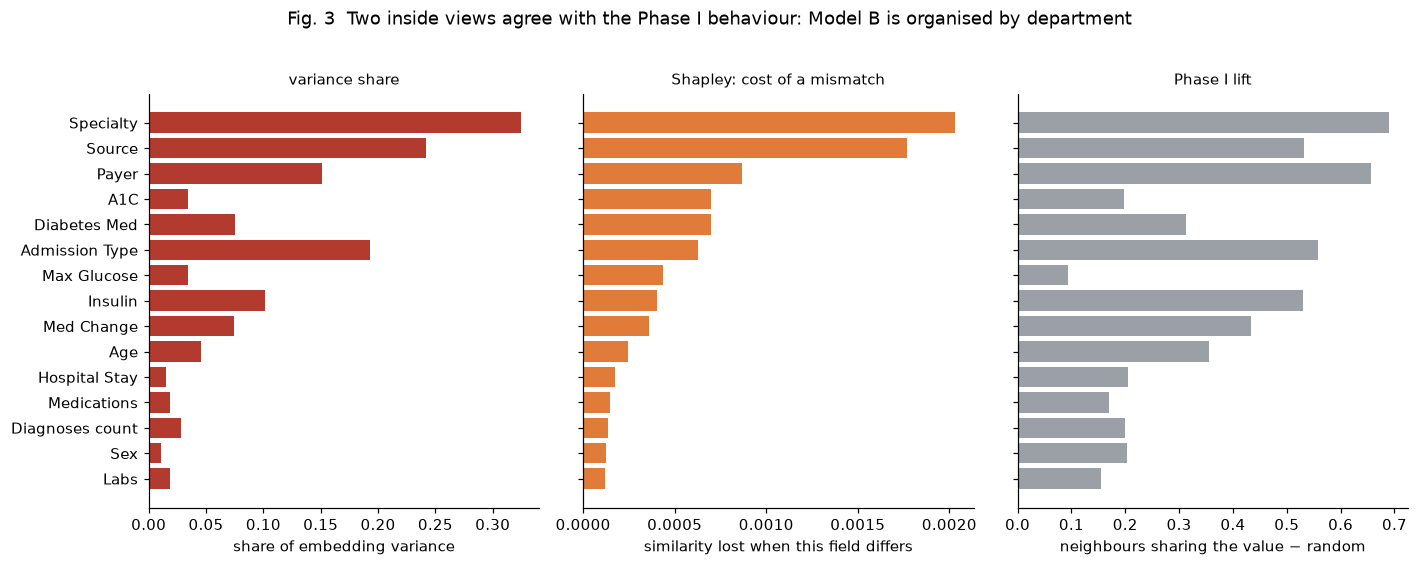

Spearman: variance vs Shapley 0.85 | Shapley vs Phase I lift 0.64
outcome (next pathway) variance share: 0.0015


,variance share,Shapley: cost of a mismatch,Phase I lift
Labs,0.0183,0.0001,0.1546
Sex,0.0110,0.0001,0.2041
Diagnoses count,0.0278,0.0001,0.1989
Medications,0.0184,0.0001,0.1695
Hospital Stay,0.0151,0.0002,0.2057
Age,0.0456,0.0002,0.3562
Med Change,0.0745,0.0004,0.4334
Insulin,0.1013,0.0004,0.5292
Max Glucose,0.0341,0.0004,0.0945
Admission Type,0.1930,0.0006,0.5585


In [5]:
from_field = {"Sex": "gender", "Age": "age", "Hospital Stay": "time_in_hospital", "Admission Type": "admission_type",
              "Source": "admission_source", "Specialty": "medical_specialty", "Payer": "payer_code",
              "Labs": "num_lab_procedures", "Medications": "num_medications", "Diagnoses count": "number_diagnoses",
              "Max Glucose": "max_glu_serum", "A1C": "A1Cresult", "Insulin": "insulin", "Med Change": "change",
              "Diabetes Med": "diabetesMed"}
pos = pd.Index(df["encounter_id"])
NB = {m: pos.get_indexer(np.concatenate(df[f"{m}_neighbors"].to_numpy())).reshape(len(df), -1) for m in ["model_b", "random"]}
numeric = {"time_in_hospital", "num_lab_procedures", "num_medications", "number_diagnoses"}
lift = {}
for label, col in from_field.items():
    v = df[col]
    v = (pd.qcut(v.rank(method="first"), 4, labels=False) if col in numeric else pd.Series(pd.factorize(v)[0])).to_numpy()
    lift[label] = (v[NB["model_b"]] == v[:, None]).mean() - (v[NB["random"]] == v[:, None]).mean()

var = pd.read_csv(OUT / "field_variance_B.csv").query("layer == 12").set_index("field").r2
sh = pd.read_parquet(OUT / "field_shapley_B.parquet")
cost = -sh[sh.differs & sh.kind.eq("random")].groupby("field").phi.mean()
tab = pd.DataFrame({"variance share": var.drop("next pathway (outcome)"), "Shapley: cost of a mismatch": cost,
                    "Phase I lift": pd.Series(lift)}).sort_values("Shapley: cost of a mismatch")
fig, axes = plt.subplots(1, 3, figsize=(13, 5), sharey=True)
for ax, colname, color in zip(axes, tab.columns, [COL["B"], COL["B2"], COL["grey"]]):
    ax.barh(tab.index, tab[colname], color=color)
    ax.set_title(colname, fontsize=10)
axes[0].set_xlabel("share of embedding variance"); axes[1].set_xlabel("similarity lost when this field differs")
axes[2].set_xlabel("neighbours sharing the value − random")
fig.suptitle("Fig. 3  Two inside views agree with the Phase I behaviour: Model B is organised by department", y=1.02)
plt.tight_layout(); plt.show()
print("Spearman: variance vs Shapley %.2f | Shapley vs Phase I lift %.2f" % (
    tab.iloc[:, 0].corr(tab.iloc[:, 1], method="spearman"), tab.iloc[:, 1].corr(tab.iloc[:, 2], method="spearman")))
print("outcome (next pathway) variance share:", round(float(pd.read_csv(OUT / "field_variance_B.csv").query("layer == 12 and field == 'next pathway (outcome)'").r2.iloc[0]), 4))
tab.round(4)

**Fig. 3.** Both inside views put the same three administrative fields on top: **Specialty, admission source, payer**. A specialty mismatch costs about 18 times as much similarity as a sex or lab-count mismatch, and specialty alone explains about a third of the embedding variance. The clinical numbers (labs, medications, diagnoses, stay length) and sex explain 1–2 % each. The next pathway explains 0.2 %. The two inside views rank the fields alike (Spearman 0.85) and follow the Phase I lift (0.64); the main exceptions are admission type (large variance share, smaller mismatch cost) and insulin (high Phase I lift, small mismatch cost); we have not yet checked why. This is the mechanism behind the Phase I lift chart: neighbours share specialty and payer because those fields organise the space. In real neighbour pairs specialty never differed (0 of 150).

## 5. Which tokens carry the similarity? Integrated Gradients (Lecture 05)

`04_token_saliency.py`: for 150 stays, Integrated Gradients of *similarity to the 1st neighbour* with respect to the input token vectors (baseline: same sequence with every token replaced by `[PAD]`, 32 steps). Tokens are split into **template** tokens (field names, `:`, `,`, identical in every record) and **value** tokens (the patient's actual values).

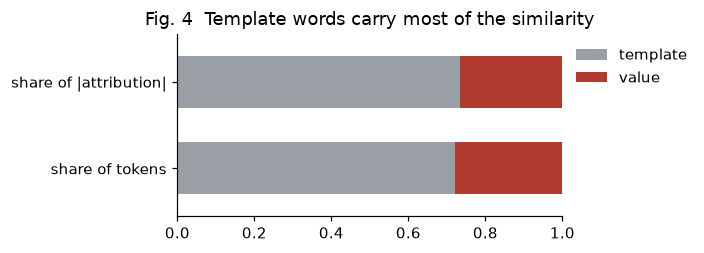

,share of tokens,share of |attribution|
part,,
template,0.72,0.733
value,0.28,0.267


In [6]:
ig = pd.read_parquet(OUT / "token_ig_B.parquet").query("part != 'special'")
share = pd.DataFrame({"share of tokens": ig.part.value_counts(normalize=True),
                      "share of |attribution|": ig.groupby("part").attr.apply(lambda s: s.abs().sum()) / ig.attr.abs().sum()})
fig, ax = plt.subplots(figsize=(6.5, 2.4))
share.T.plot.barh(stacked=True, color=[COL["grey"], COL["B"]], ax=ax, width=0.6)
ax.set_xlim(0, 1); ax.legend(frameon=False, bbox_to_anchor=(1, 1)); ax.set_title("Fig. 4  Template words carry most of the similarity")
plt.tight_layout(); plt.show()
share.round(3)

**Fig. 4.** About 70 % of the tokens are template words, and they receive about 73 % of the attribution; the patient's actual values get 27 %. This is where the shared direction of Section 2 comes from: mean pooling averages 84 token vectors of which ~60 are the same in every record. The comparison of the two techniques is informative: **Shapley over fields** says *which differences* matter (specialty, source, payer); **Integrated Gradients over tokens** says *how little room* the values have at all, because the identical template dominates the vector.

## 6. Is the outcome encoded at all, and where? Concept probes per layer

`05_layer_probes.py` adapts network dissection (Lecture 05) to a text model: for each layer a linear probe tries to read a concept from the vector (12,000 stays, split by patient). Score = balanced accuracy scaled so 0 = chance, 1 = perfect.

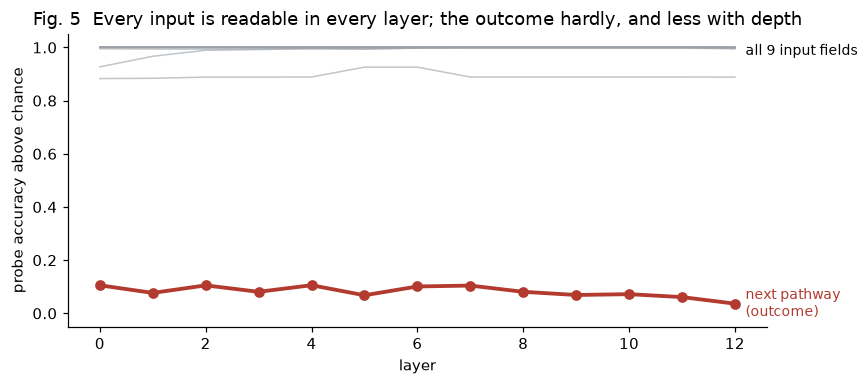

layer,0,1,2,3,4,5,6,7,8,9,10,11,12
concept,,,,,,,,,,,,,
ER + unknown specialty,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
HbA1c,0.93,0.97,0.99,0.99,1.00,0.99,1.00,1.00,1.00,1.00,1.00,1.00,1.00
admission source (top 4),1.00,0.99,0.99,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
age bracket,0.88,0.88,0.89,0.89,0.89,0.93,0.93,0.89,0.89,0.89,0.89,0.89,0.89
insulin,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
medication change,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
next pathway (outcome),0.11,0.08,0.11,0.08,0.11,0.07,0.10,0.10,0.08,0.07,0.07,0.06,0.04
payer (top 6),1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00
sex,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00,1.00


In [7]:
pr = pd.read_csv(OUT / "layer_probes_B.csv")
piv = pr.pivot(index="layer", columns="concept", values="above_chance")
fig, ax = plt.subplots(figsize=(8, 3.6))
for cpt in piv.columns:
    out = cpt.startswith("next pathway")
    ax.plot(piv.index, piv[cpt], "o-" if out else "-", color=COL["B"] if out else COL["grey"], lw=2.5 if out else 1, alpha=1 if out else 0.6)
ax.text(12.2, piv.iloc[-1].drop("next pathway (outcome)").mean(), "all 9 input fields", va="center", fontsize=9)
ax.text(12.2, piv["next pathway (outcome)"].iloc[-1], "next pathway\n(outcome)", va="center", fontsize=9, color=COL["B"])
ax.set_xlabel("layer"); ax.set_ylabel("probe accuracy above chance"); ax.set_ylim(-0.05, 1.05)
ax.set_title("Fig. 5  Every input is readable in every layer; the outcome hardly, and less with depth")
plt.tight_layout(); plt.show()
piv.T.round(2)

**Fig. 5.** All input fields can be read back almost perfectly from every layer, which is expected because they are written in the text, so "is it encoded?" is not the interesting question for inputs (Sections 3–4 ask how strongly they shape distances instead). The outcome is different: the probe is only 0.11 above chance in the first layer and **falls to 0.04 in the layer Model B uses**. The information the vote would need is barely present and BERT's layers do not add it. This is the inside explanation for the Phase I results that both models are below the majority baseline and never predict a rare pathway.

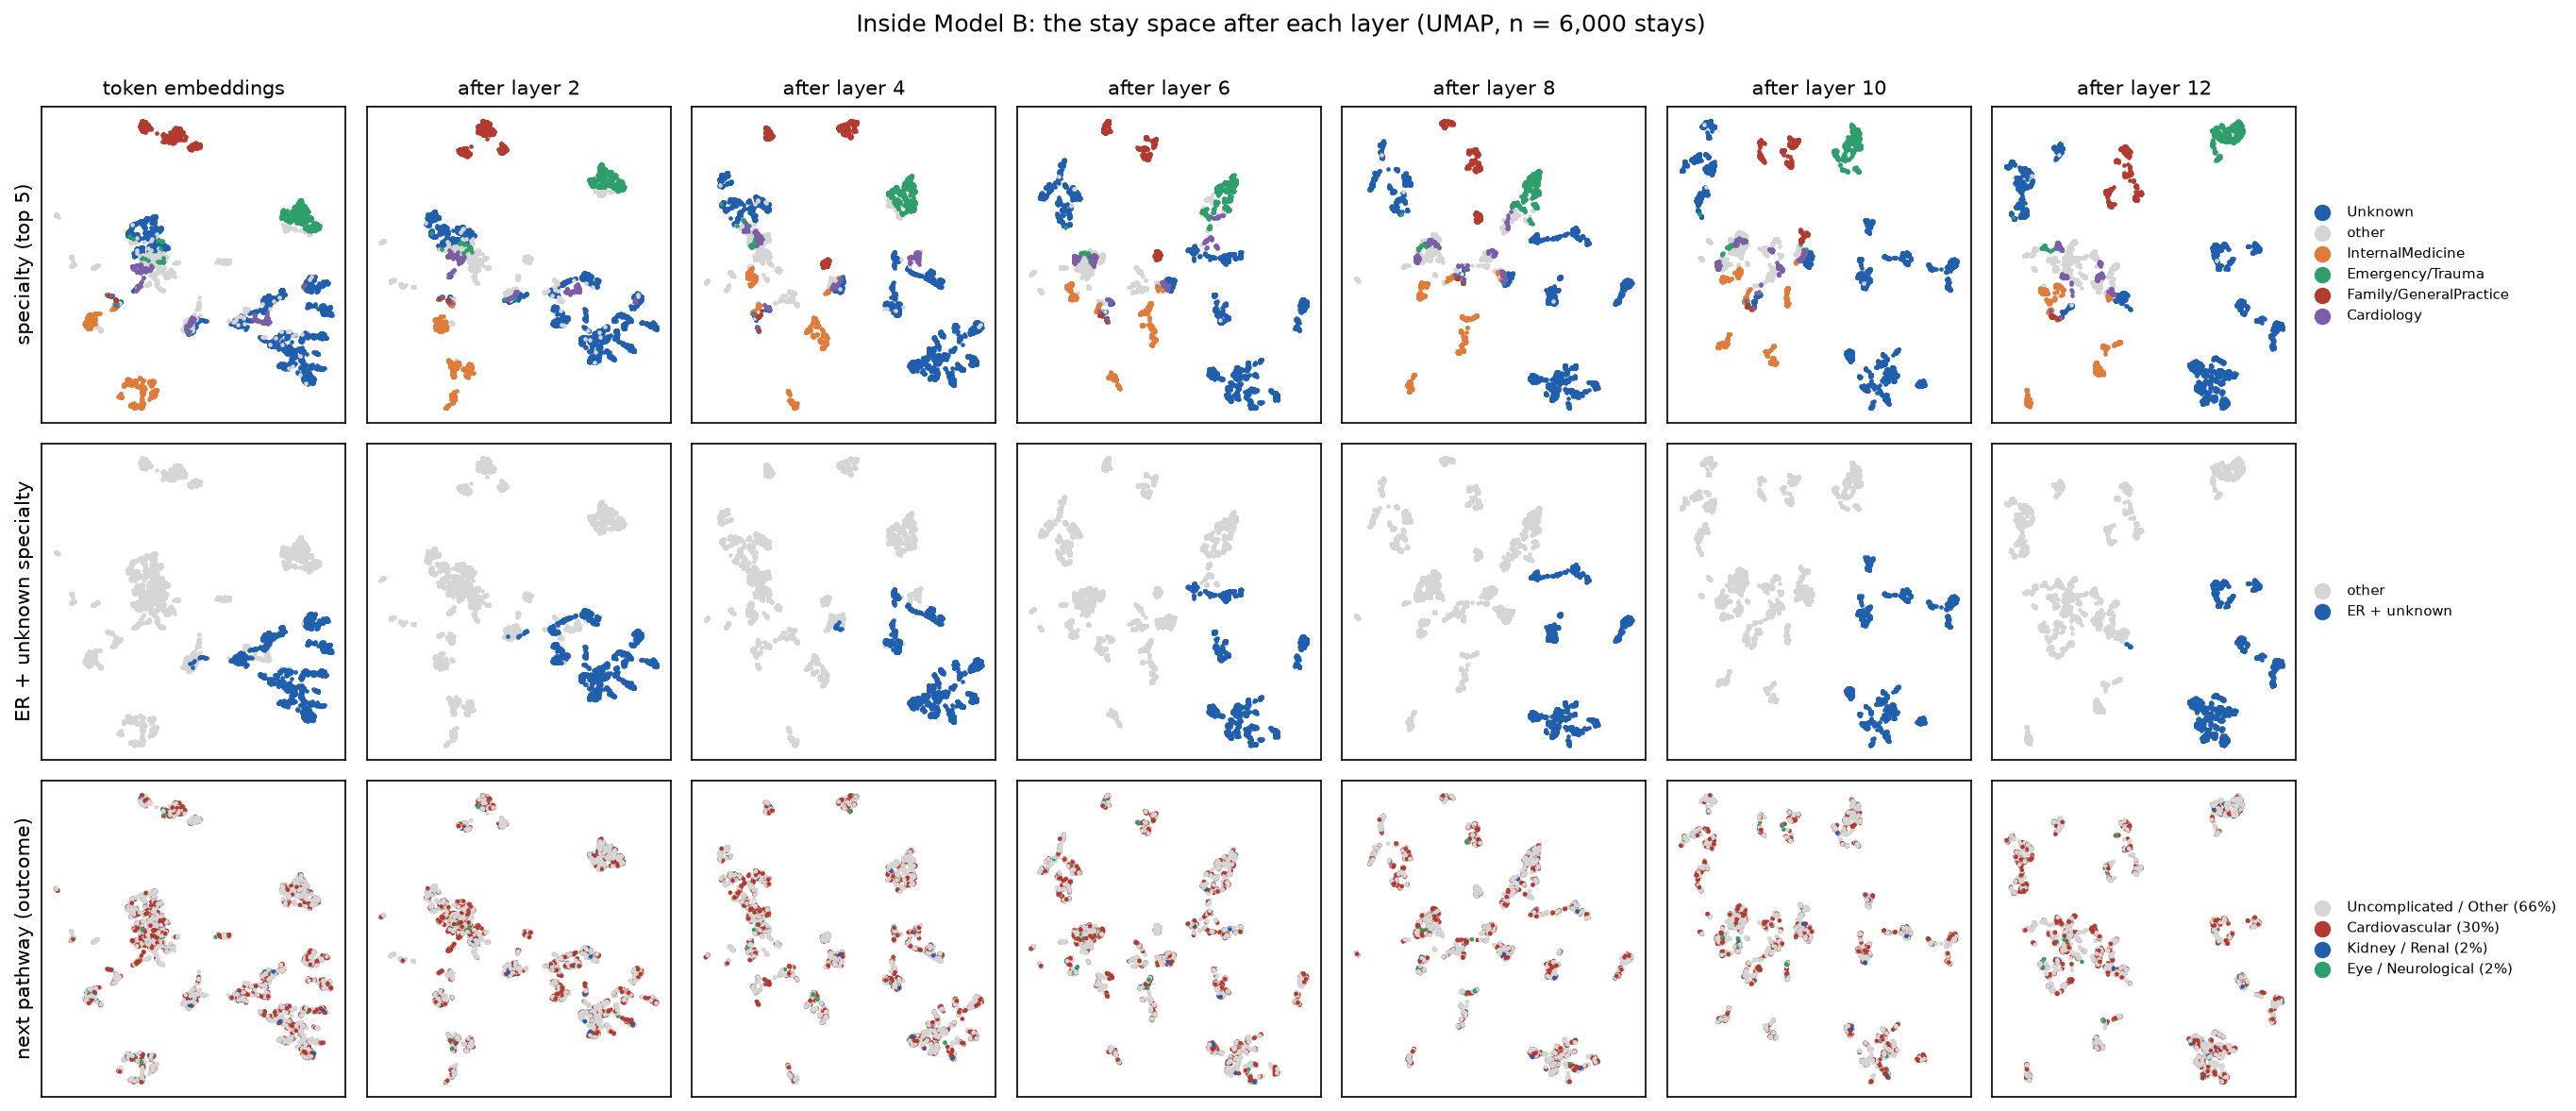

In [8]:
display(Image(FIG / "fig_layer_projection_B.png"))

**Fig. 6.** The space after each layer (UMAP of the centered vectors, each layer initialised with the previous layout). Rows colour the same stays by specialty, by the Phase I fragile group (ER + unknown specialty) and by the outcome (drawn in random order, so the colour mix in a cluster shows the real proportions). The department clusters are **already there in the token embeddings**, before any BERT layer runs, and they stay recognisable up to layer 12: Model B's neighbourhoods come from which words are in the text, and the 12 layers mainly rearrange them. The emergency + unknown-specialty stays (the most fragile group in Phase I) form their own islands at every layer. The outcome row shows no region at any depth: Cardiovascular (red) and Uncomplicated (grey) are mixed inside every cluster, and the rare pathways are scattered, so a 10-neighbour vote can only return the majority class of a department.

## 7. How Model B classifies one stay (explaining by example)

`07_walkthrough.py` follows one emergency stay with unknown specialty, the most crowded group in Phase I, through the model, before and after the HbA1c edit.

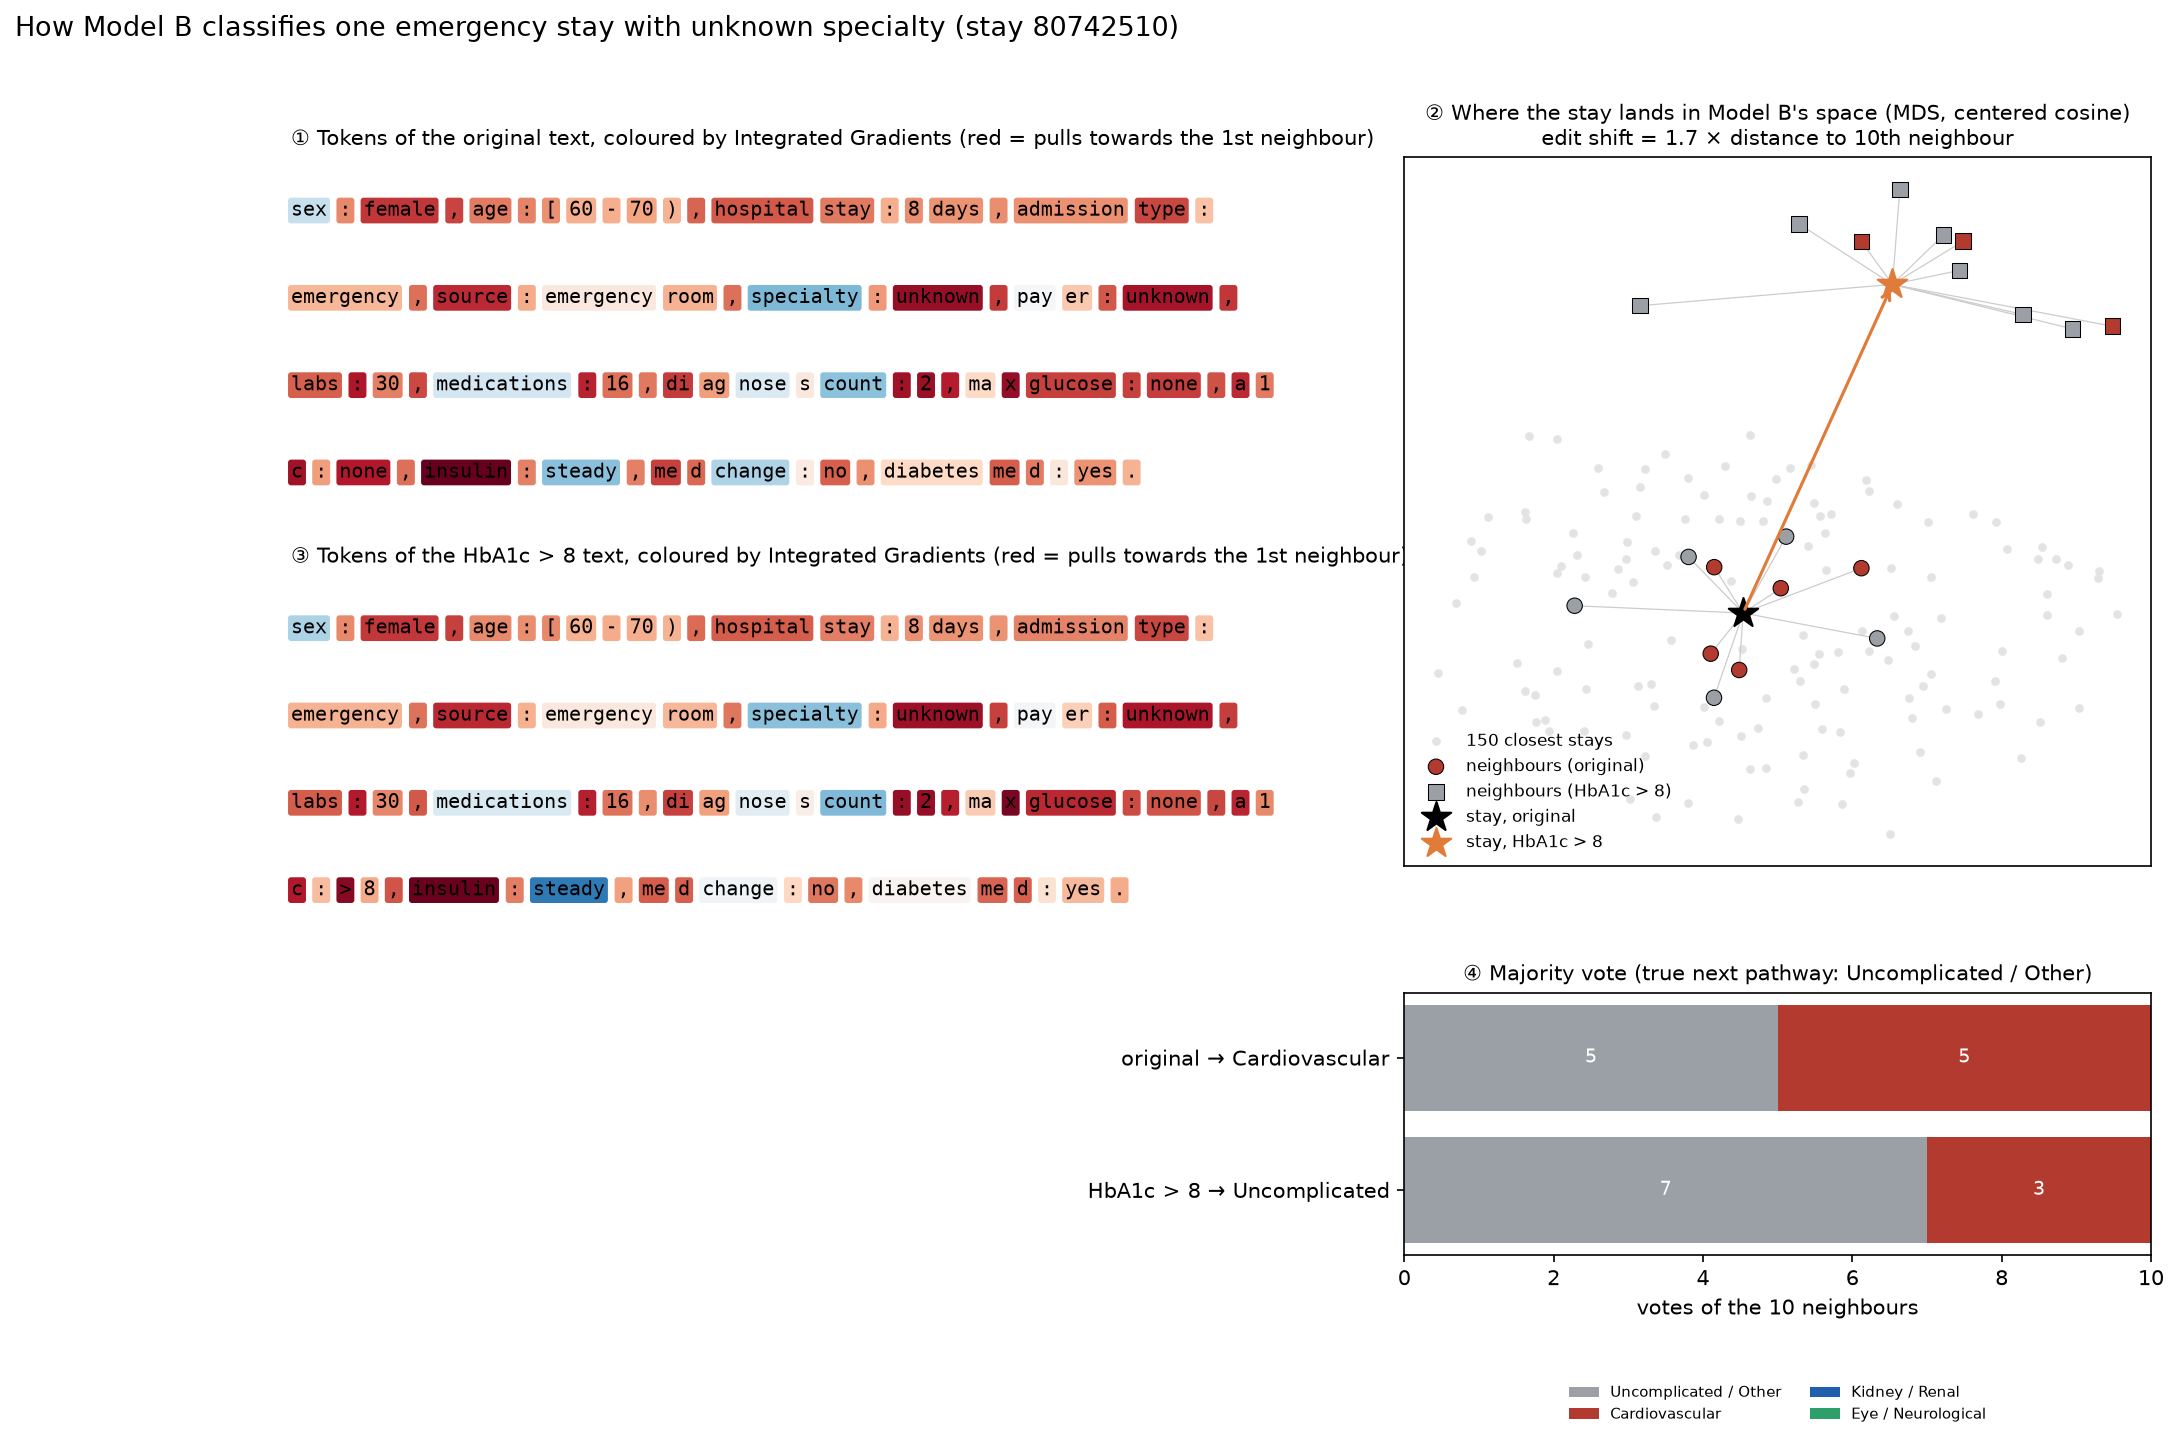

In [9]:
display(Image(FIG / "fig_walkthrough_B.png"))

**Fig. 7.** ① The tokens of the record coloured by Integrated Gradients towards the first neighbour: template words (`:`, `,`, `labs`, `source`, `insulin`) are as red as the values. ② The edit adds `>` `8` and moves the stay 1.7 × its neighbourhood radius; none of the 10 neighbours remains. ③ The vote changes from a 5:5 tie (Cardiovascular, by the best-ranked neighbour) to 7:3 Uncomplicated. The true next pathway is Uncomplicated: here the edit "fixes" the prediction, but only because the stay lands among other administrative look-alikes, not because of HbA1c's clinical meaning. Same stay, prediction and change as in Phase I.

## 8. Inside the layers: how does the classification form?

Three more techniques from Lectures 04/05, each applied layer by layer or field by field:

* **Layer-wise classifier** (`08_layer_knn.py`): Model B's own classifier (10 nearest other-patient stays, majority vote, Phase I tie rule) run on the vector after *every* layer — "what would Model B predict if it stopped after layer *l*?"
* **Grad-CAM for text** (`09_layer_gradcam.py`): Grad-CAM weights an inner layer's activations by their pooled gradients. Here: token vectors after layer *l* × mean gradient of *similarity to the 1st neighbour*, ReLU → one score per token and layer (150 stays).
* **ICE / partial dependence** (`10_ice_pdp.py`): age and HbA1c of 300 stays set to every possible value; the stay is re-encoded and re-classified each time.

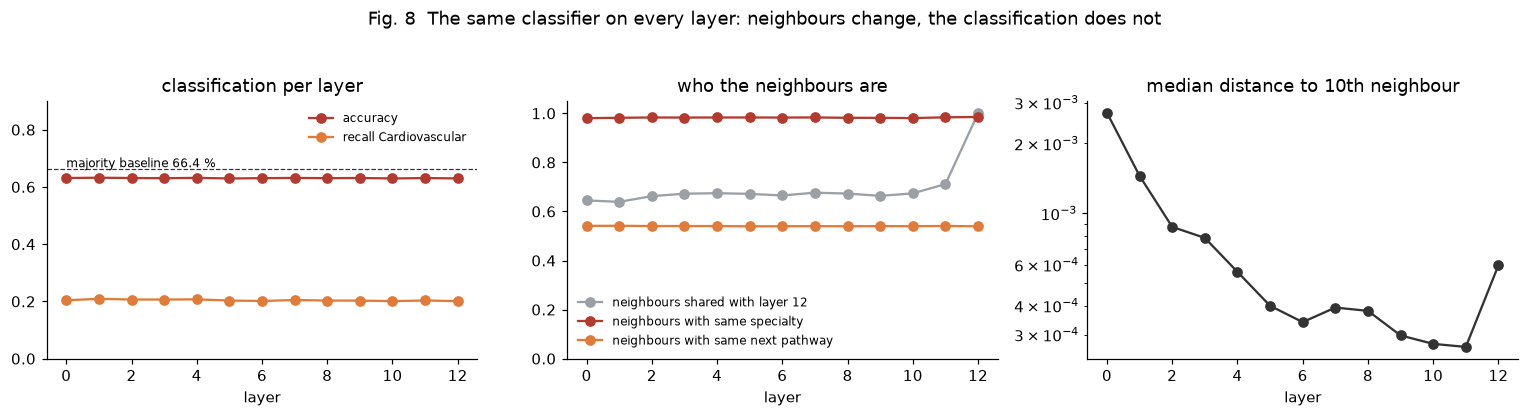

layer,0,1,2,3,4,5,6,7,8,9,10,11,12
accuracy,0.6312,0.6322,0.6311,0.6305,0.6316,0.6295,0.6306,0.6314,0.6306,0.6312,0.6296,0.6310,0.6297
recall Cardiovascular,0.2040,0.2090,0.2065,0.2065,0.2071,0.2029,0.2015,0.2049,0.2029,0.2027,0.2010,0.2032,0.2009
recall Kidney / Renal,0.0013,0.0013,0.0026,0.0026,0.0026,0.0013,0.0013,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
recall Eye / Neurological,0.0000,0.0000,0.0000,0.0000,0.0000,0.0018,0.0018,0.0018,0.0018,0.0018,0.0018,0.0018,0.0000
overlap_with_final,0.6451,0.6390,0.6626,0.6724,0.6744,0.6716,0.6653,0.6766,0.6729,0.6636,0.6737,0.7117,1.0000
same_specialty,0.9803,0.9819,0.9831,0.9828,0.9831,0.9831,0.9828,0.9832,0.9818,0.9816,0.9807,0.9837,0.9852
same_pathway,0.5412,0.5417,0.5405,0.5405,0.5405,0.5393,0.5397,0.5399,0.5397,0.5401,0.5399,0.5408,0.5394
median_d10,0.0027,0.0014,0.0009,0.0008,0.0006,0.0004,0.0003,0.0004,0.0004,0.0003,0.0003,0.0003,0.0006


In [10]:
lk = pd.read_csv(OUT / "layer_knn_B.csv")
fig, axes = plt.subplots(1, 3, figsize=(14, 3.6))
axes[0].plot(lk.layer, lk.accuracy, "o-", color=COL["B"], label="accuracy")
axes[0].axhline(lk.majority_baseline[0], color=COL["dark"], ls="--", lw=0.8)
axes[0].text(0, lk.majority_baseline[0] + 0.005, "majority baseline 66.4 %", fontsize=8)
axes[0].plot(lk.layer, lk["recall Cardiovascular"], "o-", color=COL["B2"], label="recall Cardiovascular")
axes[0].set_ylim(0, 0.9); axes[0].set_title("classification per layer"); axes[0].legend(frameon=False, fontsize=8)
axes[1].plot(lk.layer, lk.overlap_with_final, "o-", color=COL["grey"], label="neighbours shared with layer 12")
axes[1].plot(lk.layer, lk.same_specialty, "o-", color=COL["B"], label="neighbours with same specialty")
axes[1].plot(lk.layer, lk.same_pathway, "o-", color=COL["B2"], label="neighbours with same next pathway")
axes[1].set_ylim(0, 1.05); axes[1].set_title("who the neighbours are"); axes[1].legend(frameon=False, fontsize=8)
axes[2].plot(lk.layer, lk.median_d10, "o-", color=COL["dark"]); axes[2].set_yscale("log")
axes[2].set_title("median distance to 10th neighbour")
for ax in axes: ax.set_xlabel("layer")
fig.suptitle("Fig. 8  The same classifier on every layer: neighbours change, the classification does not", y=1.04)
plt.tight_layout(); plt.show()
lk[["layer", "accuracy", "recall Cardiovascular", "recall Kidney / Renal", "recall Eye / Neurological",
    "overlap_with_final", "same_specialty", "same_pathway", "median_d10"]].round(4).set_index("layer").T

**Fig. 8.** If Model B stopped after the token embeddings (layer 0), before any transformer layer, it would classify exactly as well: 63.1 % accuracy vs. 63.0 % at layer 12, Cardiovascular recall 20 %, rare pathways 0 % at every depth. The layers do change *which* stays are chosen (only 65–71 % of the neighbours of layers 0–11 survive to layer 12), but every layer picks neighbours from the same department (98 % same specialty) and with the same outcome mix (54 % same next pathway). The layers only reshuffle within a department and squeeze the space: the median distance to the 10th neighbour falls tenfold from 0.003 (layer 0) to 0.0003 (layer 11) and widens again slightly in the last layer (0.0006), matching the random-pair cosine of Fig. 1 (0.997 at layer 11, 0.995 at layer 12). How Model B classifies is fixed by which words are in the text, before BERT's layers run.

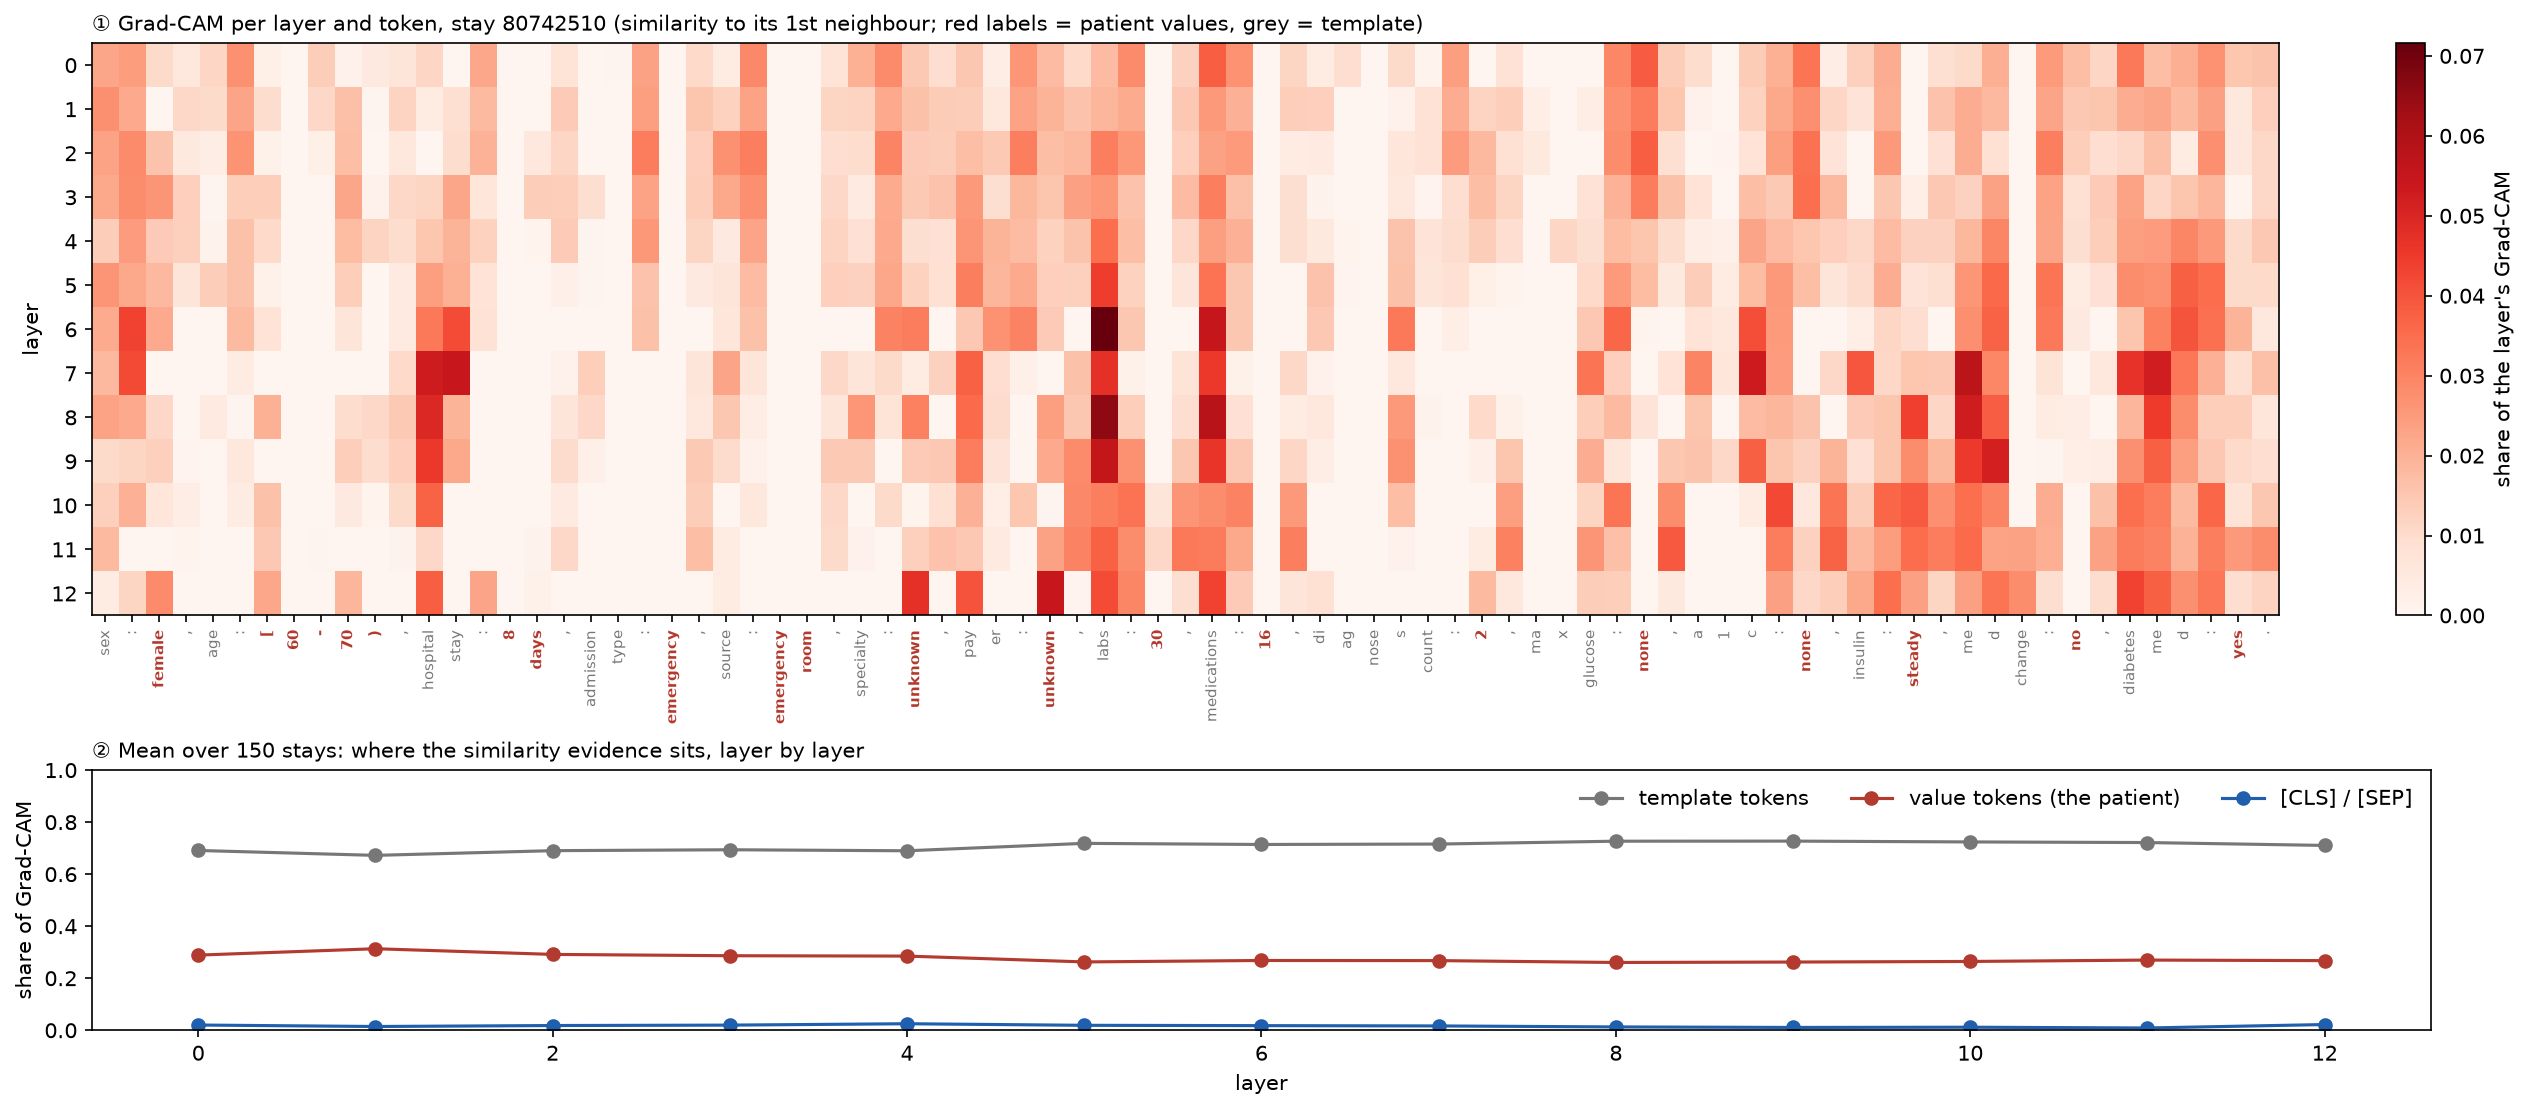

layer,0,1,2,3,4,5,6,7,8,9,10,11,12
part,,,,,,,,,,,,,
special,0.020,0.014,0.018,0.020,0.025,0.019,0.018,0.017,0.013,0.011,0.012,0.009,0.022
template,0.691,0.672,0.690,0.694,0.690,0.718,0.714,0.716,0.727,0.727,0.724,0.722,0.710
value,0.289,0.313,0.292,0.286,0.285,0.263,0.268,0.268,0.261,0.262,0.264,0.270,0.268


In [11]:
display(Image(FIG / "fig_layer_gradcam_B.png"))
gc = pd.read_parquet(OUT / "layer_gradcam_B.parquet")
(gc.groupby(["layer", "part"]).cam_share.sum().unstack() / gc.q.nunique()).round(3).T

**Fig. 9.** ② Over 150 stays, about 70 % of the Grad-CAM mass sits on template tokens in **every** layer, close to their share of tokens (70 %); no layer concentrates the evidence on the patient's values (29 % at layer 0, 27 % at layer 12). This agrees with Integrated Gradients (Fig. 4) at the input, now for every layer. ① For the walk-through stay the evidence moves through the layers: the middle layers (6–9) focus on field names (`labs`, `medications`, `stay`), and only the last layer puts the strongest weight on `unknown` (specialty and payer). This is one stay, an illustration rather than a rule. Grad-CAM mass also grows with the number of tokens of a value (age `[ 60 - 70 )` is five tokens), so per-field shares must be read with that in mind.

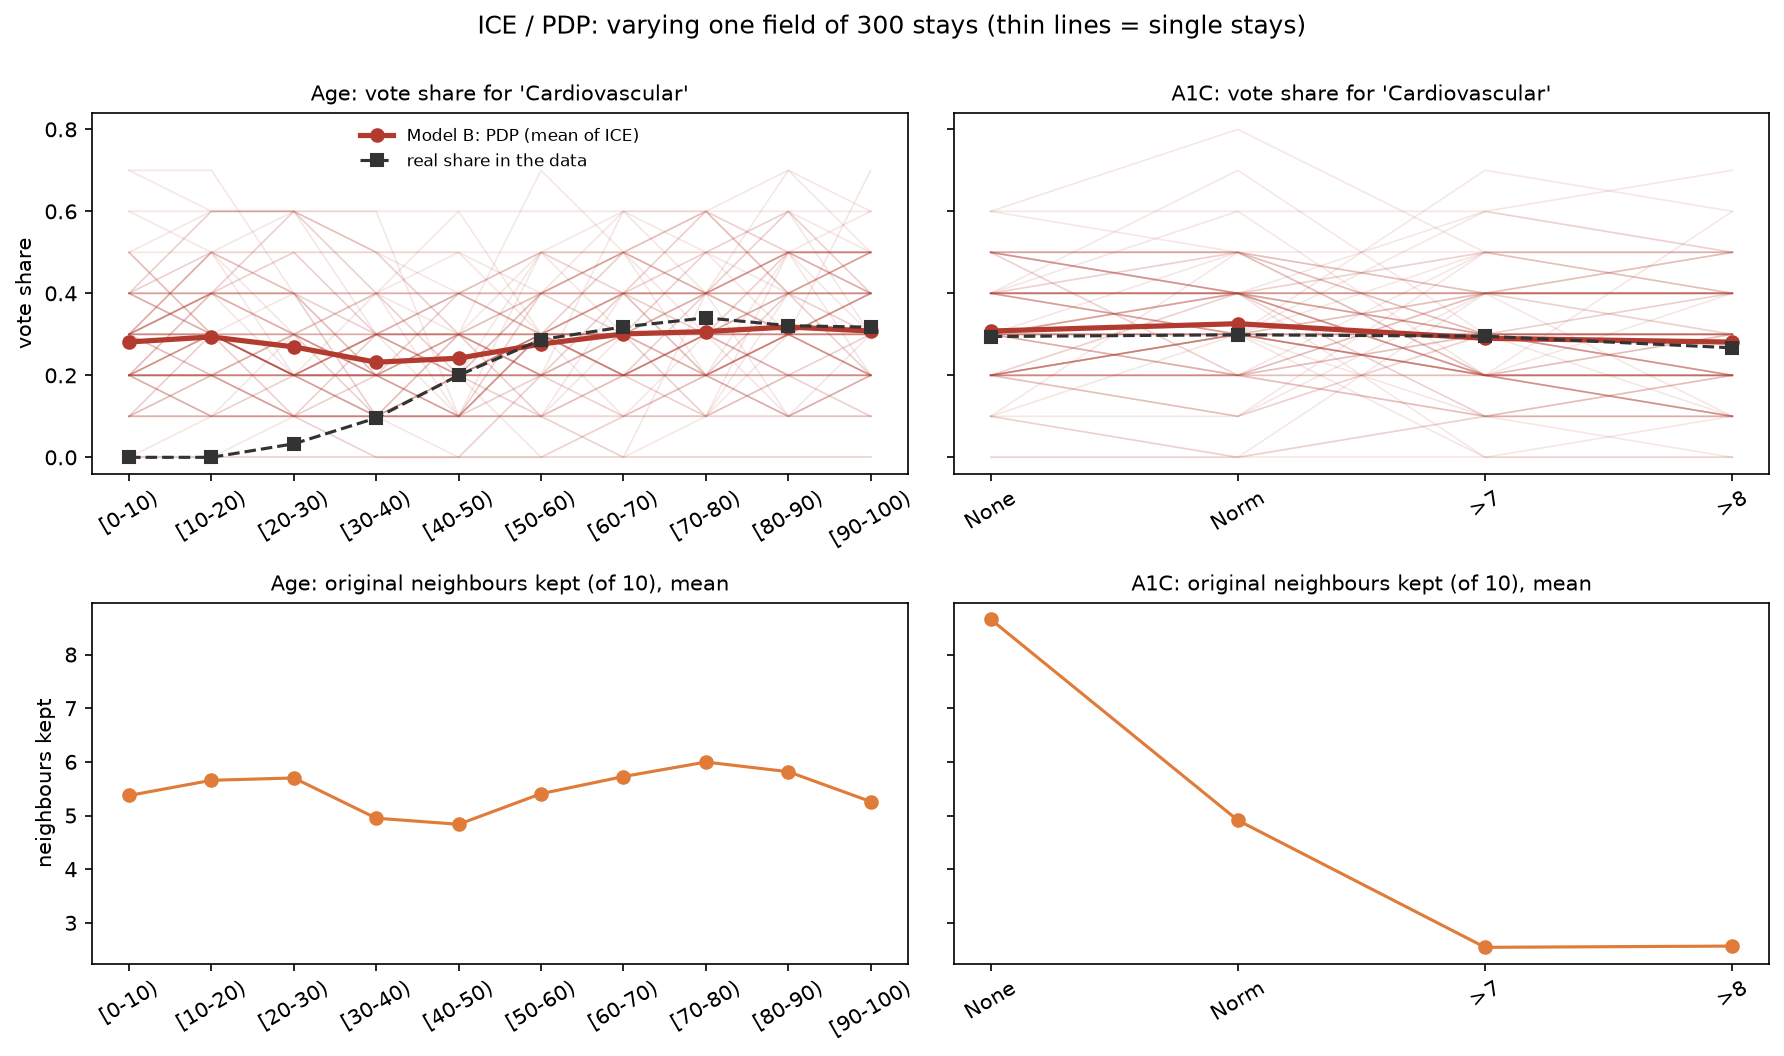

vote_share_cardio  kept_neighbours
field value                                       
A1C   >7                    0.290            2.543
      >8                    0.281            2.567
      None                  0.308            8.657
      Norm                  0.326            4.910
Age   [0-10)                0.281            5.373
      [10-20)               0.294            5.657
      [20-30)               0.269            5.700
      [30-40)               0.232            4.950
      [40-50)               0.242            4.837
      [50-60)               0.276            5.407
      [60-70)               0.301            5.727
      [70-80)               0.307            5.997
      [80-90)               0.318            5.817
      [90-100)              0.308            5.260

In [12]:
display(Image(FIG / "fig_ice_pdp_B.png"))
ice = pd.read_parquet(OUT / "ice_B.parquet")
ice.groupby(["field", "value"])[["vote_share_cardio", "kept_neighbours"]].mean().round(3)

**Fig. 10.** *Age:* in the data the share of Cardiovascular next stays rises from 0 % under 20 to 34 % at 70–80 (dashed). Model B's partial dependence is almost flat (23–32 %) and gives a teenager a higher Cardiovascular vote (29 %) than a 40-year-old (24 %): the age risk is in the data, but Model B does not use it ([0-10) has only 8 real stays; the other brackets ≥ 166). The ICE lines jump up and down by 0.1–0.3 between neighbouring brackets, and changing the age keeps only about 5 of 10 neighbours: age acts as wording, not as an ordered quantity. *HbA1c:* setting it to ">7" or ">8" keeps only 2.5 of 10 neighbours, "Norm" keeps 4.9 — the format effect of Section 3 (`>` plus a number), while the vote share stays flat, as does the real rate.

## 9. Answers

| RQ | Phase I (behaviour) | Phase II (mechanism inside Model B) |
|---|---|---|
| RQ2 confidence | Distance gap is a stability signal, not confidence | All stays sit in a narrow cone (random cosine 0.995); distances measure the template, not the patient |
| RQ3 bias | Neighbours share specialty/payer, not outcome; sex only weakly | Specialty, source, payer shape ~⅔ of the space; sex 1 %; outcome 0.2 % (variance + Shapley agree) |
| RQ4 edits | HbA1c replaces 8.2/10, sex 4.1/10 | Edit shift / neighbourhood radius: 1.33 vs. 0.18; `None` → `>` `8` adds a token, mean pooling moves |
| RQ1/RQ5 rare pathways | Never predicted | Outcome barely decodable (0.04 above chance in layer 12) and fades with depth |
| RQ1 errors | Accuracy 63.0 % < majority 66.4 % | The classifier is already as good (and as bad) after the token embeddings (63.1 %); the 12 layers reshuffle neighbours within a department; age risk present in the data is not used (flat PDP) |

**How Model B classifies, in one sentence:** it averages ~84 token vectors, of which ~60 are the identical template, so stays end up in a narrow cone ordered by department words (specialty, admission source, payer); the 10 nearest stays come from the same department, and their majority — mostly "Uncomplicated" — becomes the prediction, whatever the patient's age or HbA1c.

**Limitations.** Shapley values on 300 pairs × 20 permutations (sampling); IG depends on the `[PAD]` baseline; Grad-CAM mass depends on token counts; probes are linear; the layer UMAPs show local structure only; ICE on 300 stays. Model A gets the same field Shapley game next, so the two models can be compared directly.